In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('ecommerce_sales_34500.csv')

In [3]:
df.head()

,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,23-12-2023,4,West,No,139.47,7.88,31.17,60,Female
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,03-04-2025,6,South,No,24.73,4.60,-2.62,37,Male
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,08-10-2024,4,North,No,166.80,6.58,13.44,34,Male
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,14-09-2024,6,South,No,63.67,5.50,2.14,21,Female
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,21-12-2024,6,East,No,13.88,2.74,1.15,39,Male


In [4]:
df.isna().sum()

order_id              0
customer_id           0
product_id            0
category              0
price                 0
discount              0
quantity              0
payment_method        0
order_date            0
delivery_time_days    0
region                0
returned              0
total_amount          0
shipping_cost         0
profit_margin         0
customer_age          0
customer_gender       0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34500 entries, 0 to 34499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            34500 non-null  str    
 1   customer_id         34500 non-null  str    
 2   product_id          34500 non-null  str    
 3   category            34500 non-null  str    
 4   price               34500 non-null  float64
 5   discount            34500 non-null  float64
 6   quantity            34500 non-null  int64  
 7   payment_method      34500 non-null  str    
 8   order_date          34500 non-null  str    
 9   delivery_time_days  34500 non-null  int64  
 10  region              34500 non-null  str    
 11  returned            34500 non-null  str    
 12  total_amount        34500 non-null  float64
 13  shipping_cost       34500 non-null  float64
 14  profit_margin       34500 non-null  float64
 15  customer_age        34500 non-null  int64  
 16  customer_gender

In [6]:
df.shape

(34500, 17)

In [7]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'category', 'price',
       'discount', 'quantity', 'payment_method', 'order_date',
       'delivery_time_days', 'region', 'returned', 'total_amount',
       'shipping_cost', 'profit_margin', 'customer_age', 'customer_gender'],
      dtype='str')

In [8]:
print(df.duplicated().sum())

0


In [9]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
34495    False
34496    False
34497    False
34498    False
34499    False
Length: 34500, dtype: bool

In [10]:
df.describe()


,price,discount,quantity,delivery_time_days,total_amount,shipping_cost,profit_margin,customer_age
count,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000
mean,119.391632,0.049291,1.490725,4.814203,170.008494,6.152120,28.116505,43.474377
std,195.620477,0.069894,0.932270,1.242141,357.503014,2.389539,53.352947,14.980682
min,1.010000,0.000000,1.000000,3.000000,0.820000,0.000000,-6.200000,18.000000
25%,16.690000,0.000000,1.000000,4.000000,19.710000,4.420000,1.500000,31.000000
50%,45.660000,0.000000,1.000000,5.000000,56.820000,6.090000,10.550000,43.000000
75%,130.950000,0.100000,2.000000,6.000000,168.530000,7.830000,33.132500,56.000000
max,2930.470000,0.300000,5.000000,13.000000,12931.800000,15.650000,1536.170000,69.000000


In [11]:
df["order_date"].dtype

<StringDtype(na_value=nan)>

In [12]:
df["order_date"]=pd.to_datetime(df["order_date"],format="%d-%m-%Y")

In [13]:
print(df["order_date"].dtype)

datetime64[us]


In [14]:
df["order_date"]

0       2023-12-23
1       2025-04-03
2       2024-10-08
3       2024-09-14
4       2024-12-21
           ...    
34495   2025-08-13
34496   2023-12-04
34497   2025-02-01
34498   2024-03-27
34499   2025-09-11
Name: order_date, Length: 34500, dtype: datetime64[us]

In [15]:
print(df["order_date"].min())
print(df["order_date"].max())

2023-09-12 00:00:00
2025-09-11 00:00:00


EXPLORATORY DATA ANALYSIS PROCESS

In [16]:
df["customer_id"].nunique()

7903

In [17]:
df["order_id"].nunique()

34500

In [18]:
print(df["total_amount"].sum())

5865293.05


In [19]:
print(df["category"].unique())

<ArrowStringArray>
['Home', 'Grocery', 'Electronics', 'Beauty', 'Fashion', 'Toys', 'Sports']
Length: 7, dtype: str


In [20]:
df["category"].value_counts()

category
Fashion        6254
Electronics    6180
Home           5487
Toys           4247
Sports         4171
Beauty         4103
Grocery        4058
Name: count, dtype: int64

In [21]:
df["payment_method"].value_counts()

payment_method
Credit Card    12170
Debit Card      8505
COD             4160
UPI             4156
PayPal          3444
Wallet          2065
Name: count, dtype: int64

In [22]:
df["region"].value_counts()

region
South      7584
North      7572
East       6904
West       6808
Central    5632
Name: count, dtype: int64

In [23]:
#category wise total amount
df.groupby("category")["total_amount"].sum()

category
Beauty          153019.38
Electronics    3319206.50
Fashion         471545.80
Grocery          82000.51
Home           1077681.52
Sports          629825.54
Toys            132013.80
Name: total_amount, dtype: float64

In [24]:
df.groupby("region")["total_amount"].sum()

region
Central     940503.38
East       1176334.75
North      1264008.35
South      1298096.07
West       1186350.50
Name: total_amount, dtype: float64

In [25]:
df["quantity"].sum()

np.int64(51430)

7,903 unique customers
34,500 unique orders
₹5,865,293.05 total sales
Electronics → highest sales category
South → highest regional sales
51,430 total items sold

In [26]:
df.groupby("customer_id")["order_id"].count()

customer_id
C10000    2
C10001    5
C10002    5
C10003    3
C10004    3
         ..
C17995    2
C17996    3
C17997    4
C17998    4
C17999    4
Name: order_id, Length: 7903, dtype: int64

In [27]:
df["customer_gender"].value_counts()

customer_gender
Female    16818
Male      16310
Other      1372
Name: count, dtype: int64

In [28]:
print(df.groupby("customer_id")["order_id"].count().mean())
#4.365 → overall average Frequency across customers 

4.3654308490446665


In [29]:
df["total_amount"].sum()/df["order_id"].nunique()

np.float64(170.00849420289853)

In [30]:
df.groupby("customer_id")["total_amount"].sum()

customer_id
C10000     210.58
C10001    3246.02
C10002     216.85
C10003     154.30
C10004     716.99
           ...   
C17995     699.48
C17996     981.94
C17997     787.04
C17998     302.48
C17999    2131.87
Name: total_amount, Length: 7903, dtype: float64

In [31]:
df.groupby("customer_id")["total_amount"].sum().mean()

np.float64(742.1603251929647)

In [32]:
df["returned"].value_counts()

returned
No     32597
Yes     1903
Name: count, dtype: int64

In [33]:
df["profit_margin"]<0

0        False
1         True
2        False
3        False
4        False
         ...  
34495     True
34496    False
34497    False
34498    False
34499    False
Name: profit_margin, Length: 34500, dtype: bool

In [34]:
(df["profit_margin"]<0).sum()

np.int64(6104)

In [35]:
df["discount"].value_counts()

discount
0.00    18939
0.05     6176
0.10     4159
0.15     2795
0.20     1727
0.30      704
Name: count, dtype: int64

In [36]:
df.groupby("region")["discount"].value_counts()

region   discount
Central  0.00        3060
         0.05        1034
         0.10         702
         0.15         446
         0.20         272
         0.30         118
East     0.00        3751
         0.05        1238
         0.10         815
         0.15         594
         0.20         360
         0.30         146
North    0.00        4202
         0.05        1350
         0.10         895
         0.15         613
         0.20         362
         0.30         150
South    0.00        4144
         0.05        1355
         0.10         914
         0.15         611
         0.20         404
         0.30         156
West     0.00        3782
         0.05        1199
         0.10         833
         0.15         531
         0.20         329
         0.30         134
Name: count, dtype: int64

In [37]:
df["customer_age"].describe()

count    34500.000000
mean        43.474377
std         14.980682
min         18.000000
25%         31.000000
50%         43.000000
75%         56.000000
max         69.000000
Name: customer_age, dtype: float64

In [38]:
df["month"]=df["order_date"].dt.to_period("M")

In [39]:
df.groupby("month")["total_amount"].sum()

month
2023-09    151135.60
2023-10    262502.74
2023-11    240286.91
2023-12    255617.03
2024-01    217766.09
2024-02    228013.98
2024-03    248176.28
2024-04    265596.66
2024-05    264875.23
2024-06    234155.38
2024-07    253369.40
2024-08    212613.20
2024-09    218873.90
2024-10    258931.27
2024-11    250572.04
2024-12    278154.19
2025-01    224390.21
2025-02    215338.19
2025-03    239346.81
2025-04    263024.03
2025-05    248527.46
2025-06    248776.28
2025-07    249593.50
2025-08    243808.50
2025-09     91848.17
Freq: M, Name: total_amount, dtype: float64

In [40]:
df["profit_margin"].mean()

np.float64(28.11650463768116)

In [41]:
#average profit per category wise
df.groupby("category")["profit_margin"].mean()

category
Beauty         11.990395
Electronics    55.723587
Fashion        20.597162
Grocery        -2.264160
Home           47.864717
Sports         38.485114
Toys            7.927773
Name: profit_margin, dtype: float64

In [42]:
#negative profit margin per category wise count
df[df["profit_margin"]<0]["category"].value_counts()

category
Grocery        3875
Toys            893
Fashion         511
Beauty          478
Home            172
Sports          105
Electronics      70
Name: count, dtype: int64

VISUALISATION:  
SALES BY CATEGORY

In [43]:
category_sales=df.groupby("category")["total_amount"].sum()
print(category_sales)

category
Beauty          153019.38
Electronics    3319206.50
Fashion         471545.80
Grocery          82000.51
Home           1077681.52
Sports          629825.54
Toys            132013.80
Name: total_amount, dtype: float64


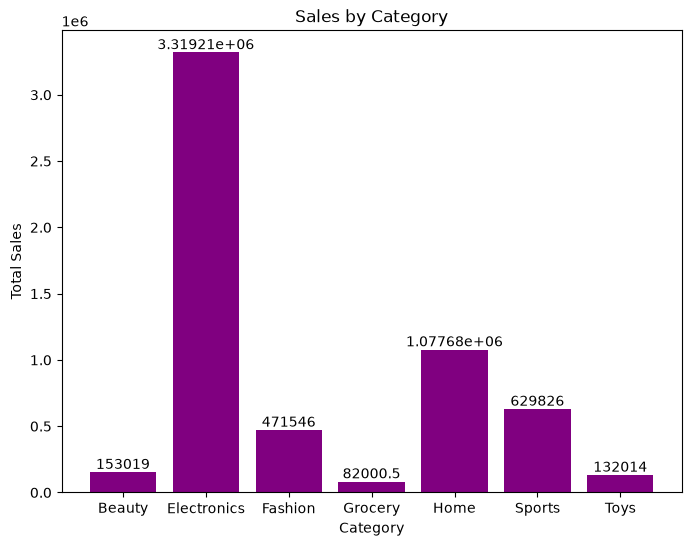

In [44]:
#category wise sales
plt.figure(figsize=(8,6))
category_sales=df.groupby("category")["total_amount"].sum()
plt.bar(category_sales.index, category_sales.values)
bars=plt.bar(category_sales.index, category_sales.values,color="purple")
plt.bar_label(bars)
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

REGION WISE TOTAL SALES

In [45]:
region_total_sales=df.groupby("region")["total_amount"].sum()
print(region_total_sales)

region
Central     940503.38
East       1176334.75
North      1264008.35
South      1298096.07
West       1186350.50
Name: total_amount, dtype: float64


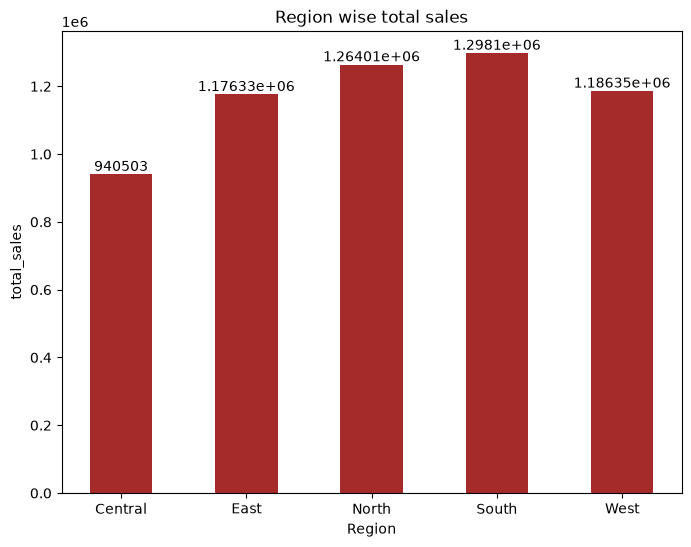

In [46]:
region_total_sales=df.groupby("region")["total_amount"].sum()
plt.figure(figsize=(8,6))
bars=plt.bar(region_total_sales.index,region_total_sales.values,width=0.5,color="brown")
plt.bar_label(bars)
plt.title("Region wise total sales")
plt.xlabel("Region")
plt.ylabel("total_sales")
plt.show()

MONTHLY WISE SALES TREND 📈

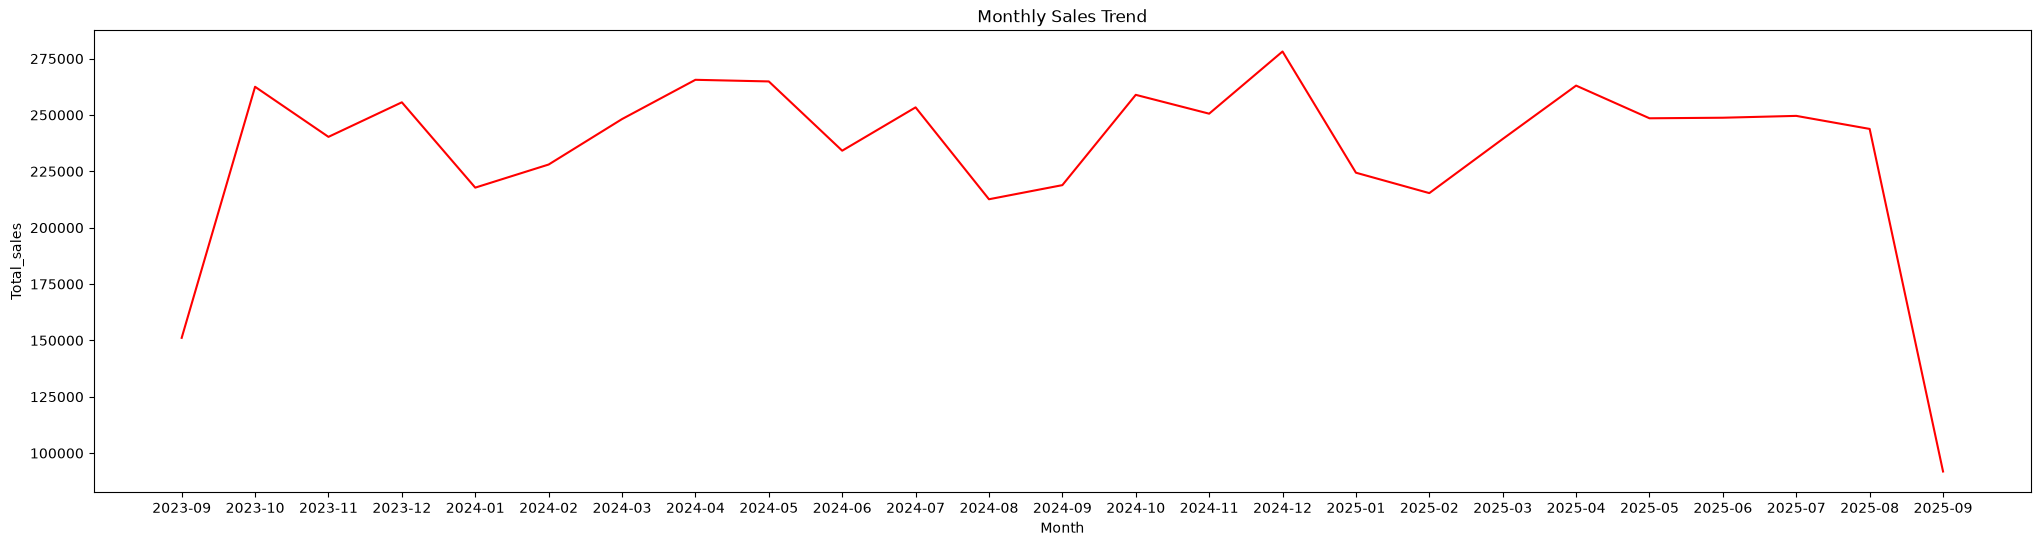

In [47]:
df["month"]=df["order_date"].dt.to_period("M")
Monthly_sales=df.groupby("month")["total_amount"].sum()
plt.figure(figsize=(25,6))
plt.plot(Monthly_sales.index.astype(str),Monthly_sales.values,color="red")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total_sales")
plt.show()



AVERAGE PROFIT MARGIN BY CATEGORY

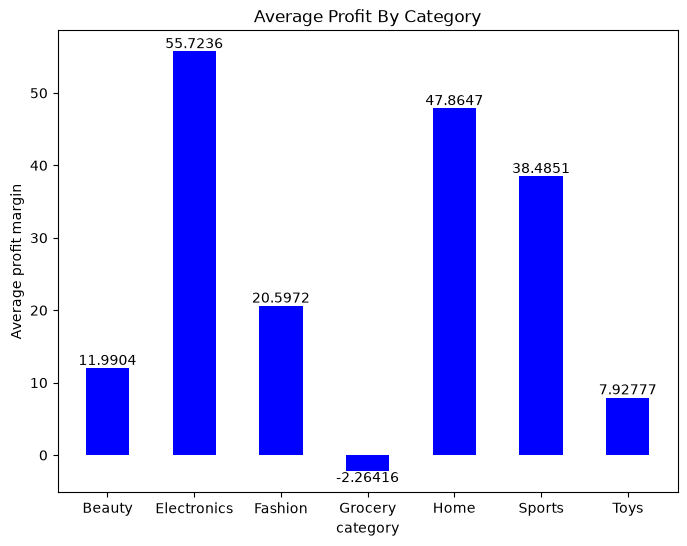

In [48]:
category_avg_profit=df.groupby("category")["profit_margin"].mean()
plt.figure(figsize=(8,6))
bars=plt.bar(category_avg_profit.index,category_avg_profit.values,color="blue",width=0.5)
plt.bar_label(bars)
plt.title("Average Profit By Category")
plt.xlabel("category")
plt.ylabel("Average profit margin")
plt.show()

RFM ANALYSIS   
R - Recency  
F - Frequency  
M - Monetary



In [49]:
# step 1 Recency
#How recently did each customer make a purchase?
df.groupby("customer_id")["order_date"].max()

customer_id
C10000   2025-09-07
C10001   2025-03-02
C10002   2024-08-07
C10003   2025-07-02
C10004   2024-01-21
            ...    
C17995   2025-02-15
C17996   2025-01-20
C17997   2024-12-03
C17998   2025-08-10
C17999   2025-07-08
Name: order_date, Length: 7903, dtype: datetime64[us]

In [50]:
reference_date=df["order_date"].max()
print("reference_date:",reference_date)
customer_last_order=df.groupby("customer_id")["order_date"].max()
print("customer_last_order:",customer_last_order)

reference_date: 2025-09-11 00:00:00
customer_last_order: customer_id
C10000   2025-09-07
C10001   2025-03-02
C10002   2024-08-07
C10003   2025-07-02
C10004   2024-01-21
            ...    
C17995   2025-02-15
C17996   2025-01-20
C17997   2024-12-03
C17998   2025-08-10
C17999   2025-07-08
Name: order_date, Length: 7903, dtype: datetime64[us]


In [51]:
recency=reference_date-customer_last_order
print("recency:",recency)

recency: customer_id
C10000     4 days
C10001   193 days
C10002   400 days
C10003    71 days
C10004   599 days
           ...   
C17995   208 days
C17996   234 days
C17997   282 days
C17998    32 days
C17999    65 days
Name: order_date, Length: 7903, dtype: timedelta64[us]


FREQUENCY - F

In [52]:
#frequency -- How many orders did each customer make?

In [53]:
customer_frequency=df.groupby("customer_id")["order_id"].count()
print("customer_frequency:",customer_frequency)


customer_frequency: customer_id
C10000    2
C10001    5
C10002    5
C10003    3
C10004    3
         ..
C17995    2
C17996    3
C17997    4
C17998    4
C17999    4
Name: order_id, Length: 7903, dtype: int64


MONETARY -- M   
How much money did each customer spend in total?

In [54]:
customer_monetary=df.groupby("customer_id")["total_amount"].sum()
print("customer_monetary:",customer_monetary)

customer_monetary: customer_id
C10000     210.58
C10001    3246.02
C10002     216.85
C10003     154.30
C10004     716.99
           ...   
C17995     699.48
C17996     981.94
C17997     787.04
C17998     302.48
C17999    2131.87
Name: total_amount, Length: 7903, dtype: float64


In [55]:
RFM=pd.concat([recency,customer_frequency,customer_monetary],axis=1)

In [56]:
RFM.to_csv("RFM.csv",index=True)

In [57]:
RFM.columns=["Recency","Frequency","Monetary"]

In [58]:
RFM.head()

,Recency,Frequency,Monetary
customer_id,,,
C10000,4 days,2,210.58
C10001,193 days,5,3246.02
C10002,400 days,5,216.85
C10003,71 days,3,154.30
C10004,599 days,3,716.99


In [59]:
RFM.tail()

,Recency,Frequency,Monetary
customer_id,,,
C17995,208 days,2,699.48
C17996,234 days,3,981.94
C17997,282 days,4,787.04
C17998,32 days,4,302.48
C17999,65 days,4,2131.87


In [60]:
RFM.shape

(7903, 3)

In [61]:
RFM.describe()

,Recency,Frequency,Monetary
count,7903,7903.000000,7903.000000
mean,158 days 00:12:12.481336,4.365431,742.160325
std,147 days 01:33:30.491804,2.048718,827.178631
min,0 days 00:00:00,1.000000,1.240000
25%,46 days 00:00:00,3.000000,215.885000
50%,114 days 00:00:00,4.000000,494.450000
75%,225 days 00:00:00,6.000000,972.460000
max,728 days 00:00:00,13.000000,13885.100000


RFM Score
Recency Score -- number of days since customer's last purchase


In [62]:
#divides into 5 equal frequency groups
pd.qcut(RFM["Recency"],5)

customer_id
C10000    (-1 days +23:59:59.999999, 35 days 00:00:00]
C10001          (150 days 00:00:00, 264 days 00:00:00]
C10002          (264 days 00:00:00, 728 days 00:00:00]
C10003            (35 days 00:00:00, 83 days 00:00:00]
C10004          (264 days 00:00:00, 728 days 00:00:00]
                              ...                     
C17995          (150 days 00:00:00, 264 days 00:00:00]
C17996          (150 days 00:00:00, 264 days 00:00:00]
C17997          (264 days 00:00:00, 728 days 00:00:00]
C17998    (-1 days +23:59:59.999999, 35 days 00:00:00]
C17999            (35 days 00:00:00, 83 days 00:00:00]
Name: Recency, Length: 7903, dtype: category
Categories (5, interval[timedelta64[us], right]): [(-1 days +23:59:59.999999, 35 days 00:00:00] < (35 days 00:00:00, 83 days 00:00:00] < (83 days 00:00:00, 150 days 00:00:00] < (150 days 00:00:00, 264 days 00:00:00] < (264 days 00:00:00, 728 days 00:00:00]]

In [63]:
RFM["R_score"]=pd.qcut(RFM["Recency"],5,labels=[5, 4, 3, 2, 1])

In [64]:
#lowest Recency → highest score.
#High Recency → lowest score
RFM[["Recency","R_score"]].head(30)

,Recency,R_score
customer_id,,
C10000,4 days,5
C10001,193 days,2
C10002,400 days,1
C10003,71 days,4
C10004,599 days,1
C10005,209 days,2
C10006,200 days,2
C10007,69 days,4
C10008,33 days,5


FREQUENCY SCORE  
Higher number of orders = better score.

In [65]:
RFM["F_score"]=pd.qcut(RFM["Frequency"],5,labels=[1, 2, 3, 4, 5])

In [66]:
#low frequency -- low score
#high frequency -- high score
RFM[["Frequency","F_score"]].head(10)

,Frequency,F_score
customer_id,,
C10000,2,1
C10001,5,3
C10002,5,3
C10003,3,1
C10004,3,1
C10005,3,1
C10006,2,1
C10007,6,4
C10008,2,1


In [67]:
RFM["M_score"]=pd.qcut(RFM["Monetary"],5,labels=[1, 2, 3, 4, 5])    

In [68]:
#High amount -- High score
#Low amount -- Low score
RFM[["Monetary","M_score"]].head(10)

,Monetary,M_score
customer_id,,
C10000,210.58,2
C10001,3246.02,5
C10002,216.85,2
C10003,154.30,1
C10004,716.99,4
C10005,216.26,2
C10006,355.74,2
C10007,734.63,4
C10008,276.66,2


In [69]:
RFM["R_score"] = RFM["R_score"].astype(int)
RFM["F_score"] = RFM["F_score"].astype(int)
RFM["M_score"] = RFM["M_score"].astype(int)

In [70]:
RFM["RFM_score"] = RFM["R_score"] + RFM["F_score"] + RFM["M_score"]

In [71]:
RFM["RFM_score"].head(10)

customer_id
C10000     8
C10001    10
C10002     6
C10003     6
C10004     6
C10005     5
C10006     5
C10007    12
C10008     8
C10009     8
Name: RFM_score, dtype: int64

In [72]:
RFM.head()

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
customer_id,,,,,,,
C10000,4 days,2,210.58,5,1,2,8
C10001,193 days,5,3246.02,2,3,5,10
C10002,400 days,5,216.85,1,3,2,6
C10003,71 days,3,154.30,4,1,1,6
C10004,599 days,3,716.99,1,1,4,6


In [73]:
RFM.to_csv("RFM_score.csv",index=True)

CUSTOMER SEGMENTATION USING MACHINE LEARNING  
-- Using K Means Clustering

In [74]:
RFM.head(10)

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
customer_id,,,,,,,
C10000,4 days,2,210.58,5,1,2,8
C10001,193 days,5,3246.02,2,3,5,10
C10002,400 days,5,216.85,1,3,2,6
C10003,71 days,3,154.30,4,1,1,6
C10004,599 days,3,716.99,1,1,4,6
C10005,209 days,3,216.26,2,1,2,5
C10006,200 days,2,355.74,2,1,2,5
C10007,69 days,6,734.63,4,4,4,12
C10008,33 days,2,276.66,5,1,2,8


In [75]:
RFM["Recency"] = RFM["Recency"].dt.days

In [76]:
RFM_features=RFM[["Recency","Frequency","Monetary"]]

In [77]:
RFM_features.head(10)

,Recency,Frequency,Monetary
customer_id,,,
C10000,4,2,210.58
C10001,193,5,3246.02
C10002,400,5,216.85
C10003,71,3,154.30
C10004,599,3,716.99
C10005,209,3,216.26
C10006,200,2,355.74
C10007,69,6,734.63
C10008,33,2,276.66


In [78]:
RFM_features.isna().sum()

Recency      0
Frequency    0
Monetary     0
dtype: int64

In [79]:
RFM_features.skew()

Recency      1.367124
Frequency    0.550169
Monetary     3.370747
dtype: float64

values transformation compressing large values reducing by using log1p and ckecking with skew()

In [80]:
#log1p() can reduce the effect of extreme values
RFM_log=np.log1p(RFM_features)

In [81]:
RFM_log.head()

,Recency,Frequency,Monetary
customer_id,,,
C10000,1.609438,1.098612,5.354603
C10001,5.267858,1.791759,8.085493
C10002,5.993961,1.791759,5.383807
C10003,4.276666,1.386294,5.045359
C10004,6.396930,1.386294,6.576456


In [82]:
#notice that the skewness went from positive to negative. That means the transformation over-corrected the distributions somewhat.
RFM_log.skew()

Recency     -0.931232
Frequency   -0.393791
Monetary    -0.734438
dtype: float64

Feature Scaling (standardize the RFM data)

In [83]:
from sklearn.preprocessing import StandardScaler

In [84]:
scaler=StandardScaler()

In [85]:
RFM_scaled=scaler.fit_transform(RFM_log)

In [86]:
#the mean used because we want to verify that StandardScaler actually standardized our features correctly.
RFM_scaled.mean(axis=0)

array([-3.41650309e-16,  4.85503071e-16, -5.22814881e-16])

Elbow method  
We need to decide how many customer groups (clusters) to create.


In [87]:
from sklearn.cluster import KMeans

Inertia = how tightly customers are grouped around their cluster centers.

In [88]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(RFM_scaled)
    inertia.append(kmeans.inertia_)

In [89]:
inertia

[14440.094673347992,
 11055.058998625223,
 9082.774957013824,
 7973.080262596162,
 7149.328966046315,
 6507.315044667822,
 5975.817365714061,
 5501.383107140407,
 5145.16689107123]

Elbow Method plot

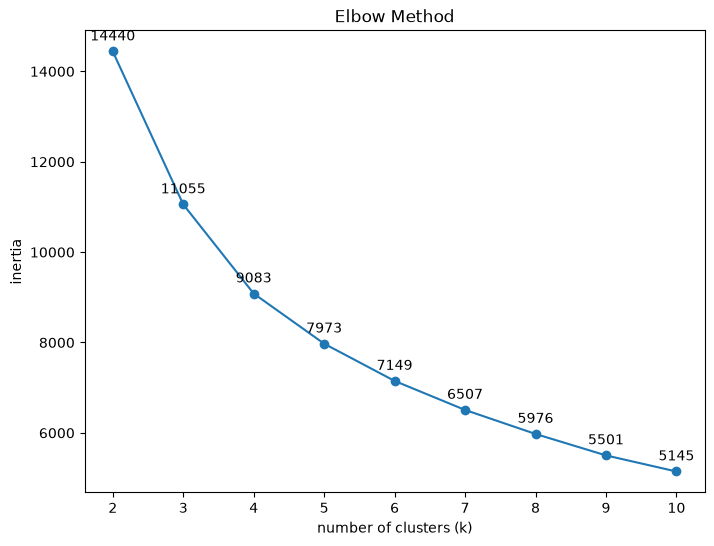

In [90]:
plt.figure(figsize=(8,6))
plt.plot(range(2,11),inertia,marker='o')
for x, y in zip(range(2, 11), inertia):
    plt.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("number of clusters (k)")
plt.ylabel("inertia")
plt.title("Elbow Method")
plt.show()

K = 4 is a reasonable choice for our customer segmentation. ✅   
But the elbow can sometimes be unclear. In your graph, the curve gradually decreases, so we want another check.

Silhouette Score

In [91]:
from sklearn.metrics import silhouette_score

In [92]:
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(RFM_scaled)
    score = silhouette_score(RFM_scaled, labels)
    silhouette_scores.append(score)


In [93]:
silhouette_scores

[0.3416811337148366,
 0.2983890810589751,
 0.26929828968747743,
 0.27053781242442304,
 0.24372203840688195,
 0.242442982297835,
 0.2484231762911776,
 0.24700579099557846,
 0.24132390493383388]

In [94]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(RFM_scaled)

RFM["Cluster"] = cluster_labels

print(RFM.head())

             Recency  Frequency  Monetary  R_score  F_score  M_score  \
customer_id                                                            
C10000             4          2    210.58        5        1        2   
C10001           193          5   3246.02        2        3        5   
C10002           400          5    216.85        1        3        2   
C10003            71          3    154.30        4        1        1   
C10004           599          3    716.99        1        1        4   

             RFM_score  Cluster  
customer_id                      
C10000               8        0  
C10001              10        2  
C10002               6        3  
C10003               6        3  
C10004               6        3  


In [95]:
RFM.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

,Recency,Frequency,Monetary
Cluster,,,
0,16.272598,5.224199,787.469630
1,283.237945,1.846640,97.967020
2,117.361945,6.239323,1368.558803
3,205.725593,3.510460,487.562193


In [96]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(RFM_scaled)

RFM["Cluster"] = cluster_labels

print(RFM.head())

             Recency  Frequency  Monetary  R_score  F_score  M_score  \
customer_id                                                            
C10000             4          2    210.58        5        1        2   
C10001           193          5   3246.02        2        3        5   
C10002           400          5    216.85        1        3        2   
C10003            71          3    154.30        4        1        1   
C10004           599          3    716.99        1        1        4   

             RFM_score  Cluster  
customer_id                      
C10000               8        0  
C10001              10        2  
C10002               6        3  
C10003               6        3  
C10004               6        3  


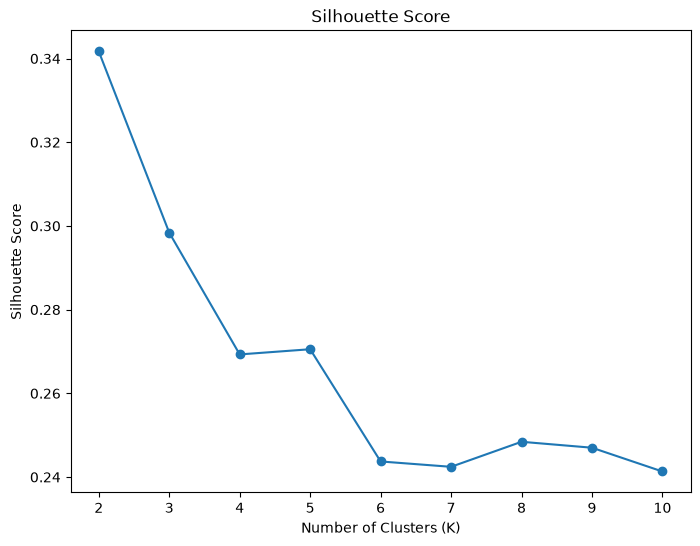

In [97]:
plt.figure(figsize=(8,6))

plt.plot(range(2,11), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")

plt.show()

In [98]:
from sklearn.decomposition import PCA

In [99]:
pca=PCA(n_components=2)

In [100]:
RFM_pca=pca.fit_transform(RFM_scaled)

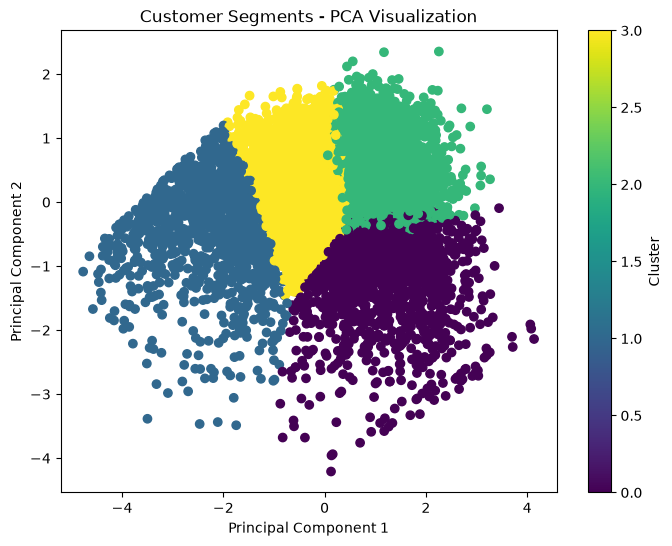

In [101]:
plt.figure(figsize=(8,6))

plt.scatter(
    RFM_pca[:, 0],
    RFM_pca[:, 1],
    c=RFM["Cluster"],
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments - PCA Visualization")
plt.colorbar(label="Cluster")

plt.show()

In [102]:
segment_names = {
    0: "Recent Active Customers",
    1: "Inactive / Low-Value Customers",
    2: "High-Value Frequent Customers",
    3: "Moderate Customers"
}

In [103]:
RFM["Segment"] = RFM["Cluster"].map(segment_names)

In [104]:
RFM.head()

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Cluster,Segment
customer_id,,,,,,,,,
C10000,4,2,210.58,5,1,2,8,0,Recent Active Customers
C10001,193,5,3246.02,2,3,5,10,2,High-Value Frequent Customers
C10002,400,5,216.85,1,3,2,6,3,Moderate Customers
C10003,71,3,154.30,4,1,1,6,3,Moderate Customers
C10004,599,3,716.99,1,1,4,6,3,Moderate Customers


In [105]:
RFM["Segment"].value_counts()

Segment
Moderate Customers                2868
High-Value Frequent Customers     2365
Recent Active Customers           1405
Inactive / Low-Value Customers    1265
Name: count, dtype: int64

In [ ]:
RFM.to_csv("RFM_customer_segments.csv")

In [107]:
RFM["Segment"]

customer_id
C10000          Recent Active Customers
C10001    High-Value Frequent Customers
C10002               Moderate Customers
C10003               Moderate Customers
C10004               Moderate Customers
                      ...              
C17995               Moderate Customers
C17996               Moderate Customers
C17997               Moderate Customers
C17998          Recent Active Customers
C17999    High-Value Frequent Customers
Name: Segment, Length: 7903, dtype: str

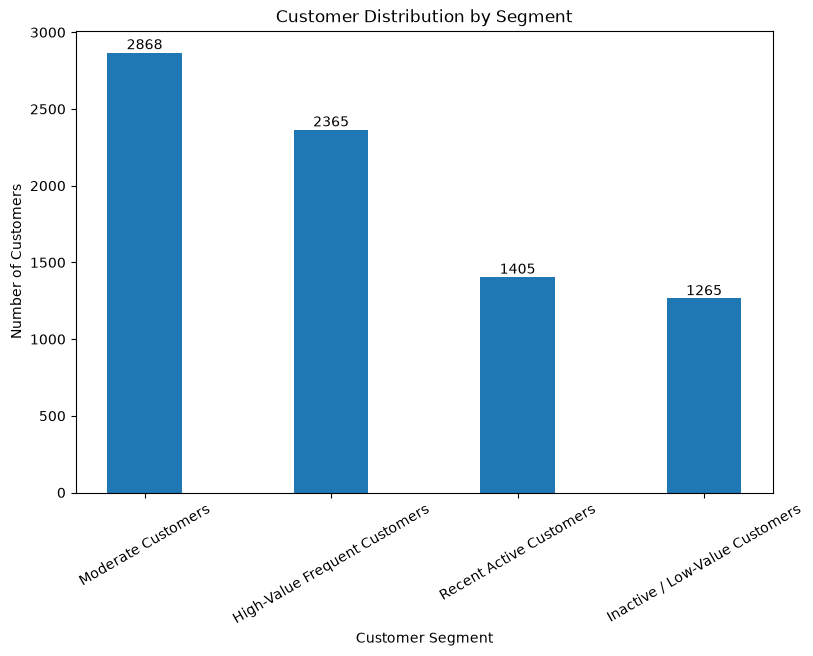

In [108]:
segment_counts = RFM["Segment"].value_counts()
plt.figure(figsize=(9,6))
bars = plt.bar(segment_counts.index, segment_counts.values, width=0.4)
plt.bar_label(bars)
plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.show()

Streamlit is a Python framework for turning your Python code into an interactive web application.